# Zomato - Part 3 : Feature Engineering for the Recommendation System

From the EDA (Part 1 & 2) we found some problems which we have to fix before building any model :

1. **Same restaurant repeated ~4 times** (listed under different `meal_type` & `city`).
   If we keep these, the recommender will recommend the *same* restaurant 4 times in a row :/
2. **~20% fake ratings** : unrated restaurants (`votes == 0`) got median `3.7` in cleaning.
3. **Raw rating is not trustworthy alone** : `4.9` from 5 votes vs `4.5` from 5000 votes ?
4. `cuisines`, `rest_type` are **multi-valued** text columns (`"North Indian, Chinese"`).
5. `cost_for_two`, `votes` are **highly skewed**.

-------------------------------------------------------

### Plan of this notebook :
1. Mark unrated restaurants properly (`rate = NaN` instead of fake 3.7)
2. Build a **restaurant level** dataset (1 row = 1 restaurant)
3. Create new features : `log_cost`, `log_votes`, `num_cuisines`, `price_category`, `meal_types` ...
4. Build a **Weighted Rating** (Bayesian average, same idea as IMDB Top 250)
5. Multi-hot encoding of `cuisines`, `rest_type`, `meal_types`
6. Build a `tags` text column (will be used for content based recommendation)
7. Save `restaurants_processed.csv` for the next notebooks

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_style('whitegrid')
sns.set_palette("husl")

plt.rcParams['figure.figsize'] = (12,6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
%matplotlib inline

In [4]:
df = pd.read_csv("zomato_cleaned.csv")
print("Shape: ", df.shape)
df.head(3)

Shape:  (51632, 12)


,address,name,online_order,book_table,rate,votes,location,rest_type,cuisines,cost_for_two,meal_type,city
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800.0,Buffet,Banashankari
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800.0,Buffet,Banashankari
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800.0,Buffet,Banashankari


## 0. Fixing broken characters in names

While checking top restaurants I found names like `SantãÂÃÂÃÂ...` :/

This is called **mojibake** : `é` was stored in UTF-8 (2 bytes : `C3 A9`), but got decoded wrongly (multiple times !) as latin-1,
so it became a long junk string. The good thing is : the **last junk character** still holds the 2nd byte of the original letter.

So the fix = find the junk run -> take its last char -> rebuild the original letter from bytes `C3 + last char`.

In [5]:
import re

junk_pattern = re.compile(r"[ãÃ][ÃÂ-¿]*")


def fix_mojibake(text):
    def repair(match):
        last = match.group(0)[-1]
        if 0x80 <= ord(last) <= 0xBF:
            return bytes([0xC3, ord(last)]).decode("utf-8", errors="replace")
        return match.group(0)
    return junk_pattern.sub(repair, text)


bad_mask = df["name"].str.contains(r"[ÃÂ]", regex=True)
print("Rows with broken names: ", bad_mask.sum())

df["name"] = df["name"].apply(fix_mojibake).str.title()
df["address"] = df["address"].apply(fix_mojibake)

print("After fixing          : ", df["name"].str.contains(r"[ÃÂ]", regex=True).sum())
print(df.loc[bad_mask, "name"].drop_duplicates().head(8).tolist())

Rows with broken names:  268
After fixing          :  0
['Café Down The Alley', 'Bohra Bohra Café', 'Foreign Café', 'E2 - Entrée Envoy', "Cocoa 'N' Crème", 'Piñata', 'Mint Spice Café & Restaurant', 'Café Felix']


## 1. Marking the Unrated restaurants

`votes == 0` => nobody rated this restaurant => the `3.7` is fake.

Will put `NaN` back in `rate` for those rows + create a flag `is_rated`.

In [6]:
df["is_rated"] = (df["votes"] > 0).astype(int)
df.loc[df["is_rated"] == 0, "rate"] = np.nan

print("Rated rows   : ", df["is_rated"].sum())
print("Unrated rows : ", (df["is_rated"] == 0).sum())

Rated rows   :  41627
Unrated rows :  10005


In [7]:
# Binary encoding (same as Part 1)
df["online_order"] = df["online_order"].map({"Yes" : 1, "No" : 0})
df["book_table"] = df["book_table"].map({"Yes" : 1, "No" : 0})

## 2. Building the Restaurant-Level dataset

A restaurant is identified by **`name` + `address`** (because chains have same name but different address).

When the same restaurant is repeated, which value should we keep ? Lets check how much the values differ inside a group first.

In [8]:
g = df.groupby(["name", "address"])

check_cols = ["rate", "votes", "cost_for_two", "location", "rest_type", "cuisines", "meal_type", "city"]

consistency = pd.DataFrame({
    "% restaurants with SAME value in all its rows" : [
        (g[col].nunique(dropna=False) == 1).mean() * 100 for col in check_cols
    ]
}, index=check_cols).round(2)

consistency

,% restaurants with SAME value in all its rows
rate,87.07
votes,68.46
cost_for_two,96.77
location,99.76
rest_type,98.93
cuisines,95.64
meal_type,43.20
city,31.39


### Observations :
- `location`, `rest_type`, `cuisines`, `cost_for_two` are almost always same -> just take the **first** / **most frequent** value.
- `rate` & `votes` differ a bit -> the data was scraped at different times, so the restaurant got some more votes in between.
  - `votes` -> take the **max** (latest snapshot)
  - `rate` -> take the **mean** (of the rated rows)
- `meal_type` & `city` differ a lot -> that's exactly why rows got repeated.
  These are actually useful info ! A restaurant listed under both `Delivery` and `Drinks & Nightlife` tells us more.
  So instead of dropping, we will **combine** them into a list : `meal_types`

### Aggregation rules :

| Column | Rule |
|---|---|
| `location`, `rest_type`, `cuisines`, `city` | most frequent value (mode) |
| `cost_for_two` | median |
| `rate` | mean (NaN ignored) |
| `votes` | max |
| `online_order`, `book_table` | max (if any listing says yes -> yes) |
| `meal_type` | all unique values joined -> `meal_types` |
| *(new)* `num_listings` | number of rows the restaurant appeared in |

In [9]:
def mode_first(x):
    # most frequent value, if tie -> first one
    return x.mode().iloc[0]


def join_unique(x):
    return ", ".join(sorted(x.unique()))


rest = df.groupby(["name", "address"], as_index=False).agg(
    location     = ("location", mode_first),
    city         = ("city", mode_first),
    rest_type    = ("rest_type", mode_first),
    cuisines     = ("cuisines", mode_first),
    cost_for_two = ("cost_for_two", "median"),
    rate         = ("rate", "mean"),
    votes        = ("votes", "max"),
    online_order = ("online_order", "max"),
    book_table   = ("book_table", "max"),
    meal_types   = ("meal_type", join_unique),
    num_listings = ("meal_type", "size"),
)

rest["rate"] = rest["rate"].round(2)
rest["is_rated"] = (rest["votes"] > 0).astype(int)

print("Shape (rows before -> after): ", df.shape[0], "->", rest.shape[0])
rest.head()

Shape (rows before -> after):  51632 -> 12463


,name,address,location,city,rest_type,cuisines,cost_for_two,rate,votes,online_order,book_table,meal_types,num_listings,is_rated
0,#Feeltheroll,"Opposite Mantri Commercio, Outer Ring Road, De...",Bellandur,Bellandur,Quick Bites,Fast Food,200.0,3.4,7,0,0,Delivery,2,1
1,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Hsr,Btm,Quick Bites,"Fast Food, Beverages",400.0,3.9,48,1,0,"Delivery, Dine-Out",9,1
2,#Refuel,"7, Ground Floor, RR Commercial Complex, Akshay...",Bannerghatta Road,Bannerghatta Road,Cafe,"Cafe, Beverages",400.0,3.7,37,1,0,"Cafes, Delivery, Dine-Out",3,1
3,#Vibes Restro,"Marasur Gate, Chandapura - Anekal Road, Near A...",Electronic City,Electronic City,Casual Dining,"Continental, Chinese, Italian",700.0,NaN,0,0,0,"Buffet, Delivery, Dine-Out",3,0
4,'Brahmins' Thatte Idli,"19, 1st main, 2nd cross, 3rd stage, 3rd block,...",Basaveshwara Nagar,Rajajinagar,Quick Bites,South Indian,100.0,NaN,0,1,0,Dine-Out,1,0


In [10]:
# Sanity check : a rated restaurant should have a rate, unrated should not

print("Rated but rate is NaN   : ", ((rest["is_rated"] == 1) & rest["rate"].isna()).sum())
print("Unrated but rate exists : ", ((rest["is_rated"] == 0) & rest["rate"].notna()).sum())

Rated but rate is NaN   :  0
Unrated but rate exists :  0


In [11]:
print(rest["is_rated"].value_counts())
print(f"\n% unrated restaurants : {(1 - rest['is_rated'].mean()) * 100:.2f}%")

is_rated
1    9459
0    3004
Name: count, dtype: int64

% unrated restaurants : 24.10%


In [12]:
rest.info()

<class 'pandas.DataFrame'>
RangeIndex: 12463 entries, 0 to 12462
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          12463 non-null  str    
 1   address       12463 non-null  str    
 2   location      12463 non-null  str    
 3   city          12463 non-null  str    
 4   rest_type     12463 non-null  str    
 5   cuisines      12463 non-null  str    
 6   cost_for_two  12463 non-null  float64
 7   rate          9459 non-null   float64
 8   votes         12463 non-null  int64  
 9   online_order  12463 non-null  int64  
 10  book_table    12463 non-null  int64  
 11  meal_types    12463 non-null  str    
 12  num_listings  12463 non-null  int64  
 13  is_rated      12463 non-null  int64  
dtypes: float64(2), int64(5), str(7)
memory usage: 1.3 MB


## 3. New Features

### 3.1 Log transforms
From Part 1 : `log1p` reduced cost skewness from `2.6` -> `0.28`. Same for votes in Part 2.

(Yeo-Johnson gave even better skew, but `log1p` is easier to interpret and good enough here, also tree models dont care much.)

In [13]:
rest["log_cost"] = np.log1p(rest["cost_for_two"])
rest["log_votes"] = np.log1p(rest["votes"])

print("Skewness :")
print(f"cost_for_two : {rest['cost_for_two'].skew():.3f}  ->  log_cost  : {rest['log_cost'].skew():.3f}")
print(f"votes        : {rest['votes'].skew():.3f}  ->  log_votes : {rest['log_votes'].skew():.3f}")

Skewness :
cost_for_two : 3.461  ->  log_cost  : 0.346
votes        : 10.289  ->  log_votes : 0.032


### 3.2 Count features

In [14]:
rest["num_cuisines"] = rest["cuisines"].str.split(",").apply(len)
rest["num_meal_types"] = rest["meal_types"].str.split(",").apply(len)

# how many outlets the same brand has -> chain or local place ?
rest["chain_size"] = rest.groupby("name")["name"].transform("count")
rest["is_chain"] = (rest["chain_size"] > 1).astype(int)

rest[["name", "num_cuisines", "num_meal_types", "chain_size", "is_chain"]].sample(5, random_state=1)

,name,num_cuisines,num_meal_types,chain_size,is_chain
3745,Fandom At Gilly'S Redefined,1,3,1,0
10770,T4U Cafe,3,3,1,0
12072,Visantoe,2,2,2,1
2574,Chin Lung Resto Bar,3,3,1,0
7965,North Tadka Restaurant,2,2,1,0


In [15]:
print("Chain restaurants (outlets) : ", rest["is_chain"].sum())
print("Single outlet restaurants   : ", (rest["is_chain"] == 0).sum())

Chain restaurants (outlets) :  5038
Single outlet restaurants   :  7425


### 3.3 Price Category (same bins as Part 1)

In [16]:
price_order = ["Budget", "Affordable", "Mid-Range", "Premium", "Luxury"]

rest["price_category"] = pd.cut(
    rest["cost_for_two"],
    bins=[0, 200, 500, 1000, 1500, np.inf],
    labels=price_order
)

# ordinal encoding : Budget=0 ... Luxury=4 (order matters here, so label/ordinal encoding is fine)
rest["price_level"] = rest["price_category"].cat.codes

rest["price_category"].value_counts().reindex(price_order)

price_category
Budget        2356
Affordable    6687
Mid-Range     2627
Premium        509
Luxury         284
Name: count, dtype: int64

## 4. Weighted Rating (Bayesian Average)

#### Problem :

In [17]:
rest[rest["is_rated"] == 1].sort_values("rate", ascending=False)[["name", "location", "rate", "votes"]].head(10)

,name,location,rate,votes
825,Asia Kitchen By Mainland China,Koramangala 5Th Block,4.90,2256
9446,Santé Spa Cuisine,Indiranagar,4.90,246
1862,Byg Brewski Brewing Company,Sarjapur Road,4.90,16832
8714,Punjab Grill,Malleshwaram,4.90,1985
3898,Flechazo,Whitefield,4.90,3004
7099,Milano Ice Cream,Indiranagar,4.90,2090
208,Ab'S - Absolute Barbecues,Btm,4.90,6490
1221,Belgian Waffle Factory,Brigade Road,4.90,1750
8715,Punjab Grill,Whitefield,4.83,654
1219,Belgian Waffle Factory,Koramangala 5Th Block,4.81,201


Most of these have `4.9`, with votes ranging from ~200 to ~17k. Should a place with 200 votes be ranked same as one with thousands of votes ?
No ! Less votes = less confidence. (and among NEW-ish restaurants with only 5-10 votes it is even worse)

-------------------------------------------------------

#### Solution : IMDB's weighted rating formula

$$ WR = \frac{v}{v+m} \cdot R + \frac{m}{v+m} \cdot C $$

where :
- `R` = restaurant's average rating
- `v` = number of votes of the restaurant
- `m` = minimum votes needed to be "trusted" (we choose this)
- `C` = mean rating across ALL rated restaurants

**Intuition :** If a restaurant has very few votes, its WR gets pulled towards the global mean `C`.
As votes increase, WR moves closer to its own rating `R`. :)

We will take `m` = **median** votes of rated restaurants.

In [18]:
rated = rest[rest["is_rated"] == 1]

C_mean = rated["rate"].mean()
m = rated["votes"].quantile(0.50)

print(f"C (mean rating)       : {C_mean:.3f}")
print(f"m (min votes, median) : {m:.0f}")

C (mean rating)       : 3.624
m (min votes, median) : 53


In [19]:
def weighted_rating(row, m=m, C=C_mean):
    v = row["votes"]
    R = row["rate"]
    if pd.isna(R):
        return np.nan
    return (v / (v + m)) * R + (m / (v + m)) * C


rest["weighted_rating"] = rest.apply(weighted_rating, axis=1).round(3)

In [20]:
rest[rest["is_rated"] == 1].sort_values("weighted_rating", ascending=False)[
    ["name", "location", "rate", "votes", "weighted_rating"]
].head(10)

,name,location,rate,votes,weighted_rating
1862,Byg Brewski Brewing Company,Sarjapur Road,4.9,16832,4.896
208,Ab'S - Absolute Barbecues,Btm,4.9,6490,4.890
3898,Flechazo,Whitefield,4.9,3004,4.878
825,Asia Kitchen By Mainland China,Koramangala 5Th Block,4.9,2256,4.871
7099,Milano Ice Cream,Indiranagar,4.9,2090,4.868
8714,Punjab Grill,Malleshwaram,4.9,1985,4.867
1221,Belgian Waffle Factory,Brigade Road,4.9,1750,4.863
212,Ab'S - Absolute Barbecues,Marathahalli,4.8,12121,4.795
11108,The Black Pearl,Marathahalli,4.8,7284,4.792
2548,Chili'S American Grill & Bar,Malleshwaram,4.8,6470,4.790


Now the top list is full of restaurants that have high rating **AND** lots of votes -> much more reliable ;)

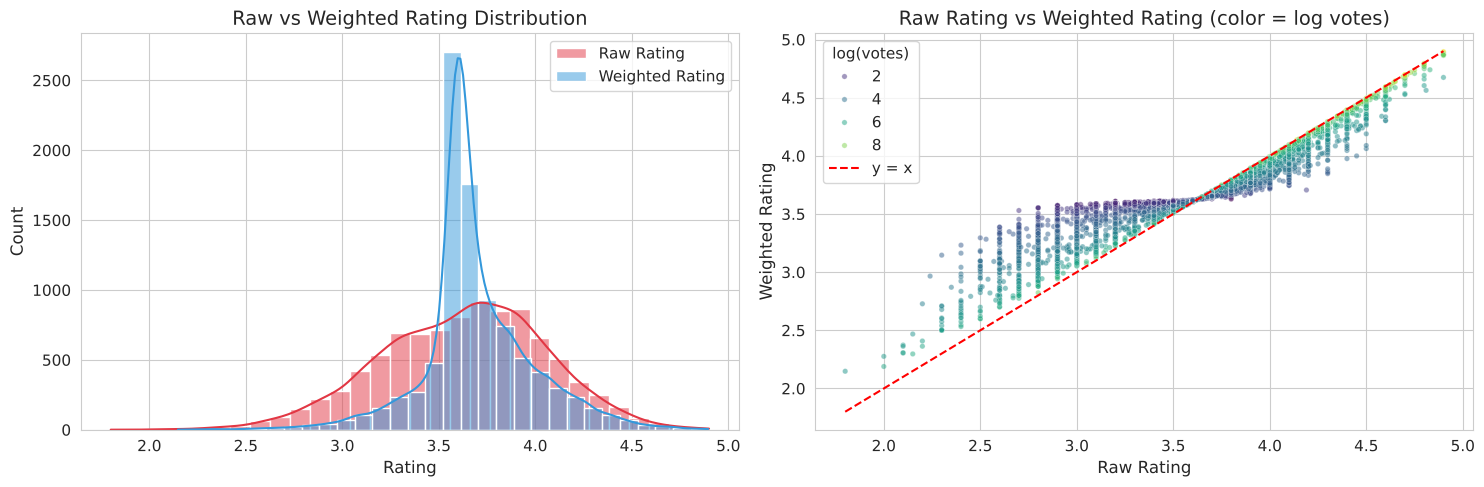

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(rated["rate"], bins=30, color="#E23744", kde=True, ax=axes[0], label="Raw Rating")
sns.histplot(rest["weighted_rating"].dropna(), bins=30, color="#3498DB", kde=True, ax=axes[0], alpha=0.5, label="Weighted Rating")
axes[0].set_title("Raw vs Weighted Rating Distribution")
axes[0].set_xlabel("Rating")
axes[0].legend()

sns.scatterplot(x="rate", y="weighted_rating", hue=np.log1p(rated["votes"]),
                data=rest[rest["is_rated"] == 1], palette="viridis", alpha=0.5, s=15, ax=axes[1])
axes[1].plot([1.8, 4.9], [1.8, 4.9], "r--", label="y = x")
axes[1].set_title("Raw Rating vs Weighted Rating (color = log votes)")
axes[1].set_xlabel("Raw Rating")
axes[1].set_ylabel("Weighted Rating")
axes[1].legend(title="log(votes)")

plt.tight_layout()
plt.savefig("plots/weighted_rating.png", dpi=150, bbox_inches="tight")
plt.show()

-------------------------------------------------------
### Insights :

- Weighted rating is **narrower** than raw rating -> extreme values with few votes got pulled to the center.
- In the scatter plot : **yellow points** (lots of votes) stay near the `y = x` line, while **dark points** (few votes) get flattened towards the mean.
- This is exactly what we wanted.

-------------------------------------------------------

## 5. Multi-Hot Encoding

`cuisines = "North Indian, Chinese"` -> we can't do simple label encoding (it would make "North Indian, Chinese" & "Chinese, North Indian" 2 different labels !)

Also OHE on the full string will create ~2700 columns.

#### Solution : Multi-Hot Encoding
Split the string -> make 1 column per cuisine -> put `1` if restaurant serves it.

| name | North Indian | Chinese | Italian |
|---|---|---|---|
| A | 1 | 1 | 0 |
| B | 0 | 0 | 1 |

`sklearn` has `MultiLabelBinarizer` for exactly this.

In [22]:
from sklearn.preprocessing import MultiLabelBinarizer


def to_list(s):
    return [x.strip() for x in s.split(",") if x.strip() != ""]


rest["cuisine_list"] = rest["cuisines"].apply(to_list)
rest["rest_type_list"] = rest["rest_type"].apply(to_list)
rest["meal_type_list"] = rest["meal_types"].apply(to_list)

rest[["cuisines", "cuisine_list"]].head()

,cuisines,cuisine_list
0,Fast Food,[Fast Food]
1,"Fast Food, Beverages","[Fast Food, Beverages]"
2,"Cafe, Beverages","[Cafe, Beverages]"
3,"Continental, Chinese, Italian","[Continental, Chinese, Italian]"
4,South Indian,[South Indian]


In [23]:
mlb_cuisine = MultiLabelBinarizer()
cuisine_ohe = pd.DataFrame(
    mlb_cuisine.fit_transform(rest["cuisine_list"]),
    columns=["cuisine_" + c for c in mlb_cuisine.classes_],
    index=rest.index
)

mlb_rest = MultiLabelBinarizer()
rest_type_ohe = pd.DataFrame(
    mlb_rest.fit_transform(rest["rest_type_list"]),
    columns=["rtype_" + c for c in mlb_rest.classes_],
    index=rest.index
)

mlb_meal = MultiLabelBinarizer()
meal_ohe = pd.DataFrame(
    mlb_meal.fit_transform(rest["meal_type_list"]),
    columns=["meal_" + c for c in mlb_meal.classes_],
    index=rest.index
)

print("Cuisine columns   : ", cuisine_ohe.shape[1])
print("Rest type columns : ", rest_type_ohe.shape[1])
print("Meal type columns : ", meal_ohe.shape[1])

Cuisine columns   :  106
Rest type columns :  26
Meal type columns :  7


Notice : `rest_type` had ~94 unique *strings*, but after splitting there are much less *actual* types
(because `"Casual Dining, Bar"` & `"Bar, Casual Dining"` are the same thing).

In [24]:
cuisine_ohe.iloc[:5, :12]

,cuisine_Afghan,cuisine_African,cuisine_American,cuisine_Andhra,cuisine_Arabian,cuisine_Asian,cuisine_Assamese,cuisine_Australian,cuisine_Awadhi,cuisine_Bakery,cuisine_Bar Food,cuisine_Bbq
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


#### Rare cuisines

Some cuisines are served by very few restaurants. Too many sparse columns = noise for ML models.
Lets see how many restaurants each cuisine has.

In [25]:
cuisine_counts = cuisine_ohe.sum().sort_values(ascending=False)

print("Cuisines served by < 20 restaurants: ", (cuisine_counts < 20).sum(), "out of", len(cuisine_counts))
cuisine_counts.tail(10)

Cuisines served by < 20 restaurants:  51 out of 106


cuisine_Australian    1
cuisine_Cantonese     1
cuisine_Bohri         1
cuisine_Mongolian     1
cuisine_Jewish        1
cuisine_Malwani       1
cuisine_Sindhi        1
cuisine_Russian       1
cuisine_Raw Meats     1
cuisine_Vegan         1
dtype: int64

We will **keep all of them** in the saved file (the recommender can use rare cuisines, eg : someone searching for `Mongolian` food !).

For the ML model in the next notebook we can decide to drop the rare ones.

## 6. Location Encoding

`location` has ~93 values. OHE would be 93 columns (ok-ish), but we can also add a few **numerical** location features
which describe *what kind of area* it is :

- `loc_rest_count` : how many restaurants in that location (busy food hub or not)
- `loc_avg_cost` : avg cost of that location (premium area or not)

> NOTE : we are **NOT** creating `loc_avg_rating` here (target encoding), because using the target (rating) to make a feature
> before the train/test split causes **data leakage**. If needed, it should be done inside the model pipeline on train data only.

In [26]:
rest["loc_rest_count"] = rest.groupby("location")["name"].transform("count")
rest["loc_avg_cost"] = rest.groupby("location")["cost_for_two"].transform("mean").round(1)

rest[["location", "loc_rest_count", "loc_avg_cost"]].drop_duplicates().sort_values("loc_avg_cost", ascending=False).head(10)

,location,loc_rest_count,loc_avg_cost
3057,Sankey Road,13,2526.9
47,Race Course Road,30,1316.7
284,Lavelle Road,55,1295.5
272,Mg Road,92,1051.6
24,Infantry Road,15,966.7
373,Residency Road,82,948.8
28,Church Street,56,761.2
678,St. Marks Road,35,755.7
36,Seshadripuram,58,733.6
338,Richmond Road,89,732.6


## 7. Tags column (for Content Based Recommendation)

For content based recommendation we need to describe each restaurant as **text**, then compare these texts (TF-IDF + cosine similarity, next notebooks).

We will combine : `cuisines + rest_type + meal_types + price_category + location`

Small trick : multi-word items like `"North Indian"` will be joined with `_` -> `north_indian`,
so that `"North"` and `"Indian"` are not treated as separate words.
(otherwise "North Indian" and "South Indian" would look similar just because of the word "Indian")

In [27]:
def make_token(s):
    return s.strip().lower().replace(" ", "_").replace("&", "and").replace("-", "_").replace(".", "")


def build_tags(row):
    tokens = []
    tokens += [make_token(c) for c in row["cuisine_list"]]
    tokens += ["rt_" + make_token(r) for r in row["rest_type_list"]]
    tokens += ["meal_" + make_token(mt) for mt in row["meal_type_list"]]
    tokens.append("price_" + make_token(str(row["price_category"])))
    tokens.append("loc_" + make_token(row["location"]))
    return " ".join(tokens)


rest["tags"] = rest.apply(build_tags, axis=1)

for i in range(3):
    print(rest.loc[i, "name"], " -> ", rest.loc[i, "tags"])

#Feeltheroll  ->  fast_food rt_quick_bites meal_delivery price_budget loc_bellandur
#L-81 Cafe  ->  fast_food beverages rt_quick_bites meal_delivery meal_dine_out price_affordable loc_hsr
#Refuel  ->  cafe beverages rt_cafe meal_cafes meal_delivery meal_dine_out price_affordable loc_bannerghatta_road


## 8. Final check & Saving

In [28]:
final_cols = [
    # identity
    "name", "address", "location", "city",
    # original info
    "rest_type", "cuisines", "meal_types", "cost_for_two", "rate", "votes",
    "online_order", "book_table",
    # engineered
    "is_rated", "weighted_rating", "log_cost", "log_votes", "price_category", "price_level",
    "num_cuisines", "num_meal_types", "num_listings", "chain_size", "is_chain",
    "loc_rest_count", "loc_avg_cost", "tags",
]

rest_final = rest[final_cols].copy()
rest_final.insert(0, "rest_id", range(len(rest_final)))   # a simple id for each restaurant

print(rest_final.shape)
rest_final.head()

(12463, 27)


,rest_id,name,address,location,city,rest_type,cuisines,meal_types,cost_for_two,rate,...,price_category,price_level,num_cuisines,num_meal_types,num_listings,chain_size,is_chain,loc_rest_count,loc_avg_cost,tags
0,0,#Feeltheroll,"Opposite Mantri Commercio, Outer Ring Road, De...",Bellandur,Bellandur,Quick Bites,Fast Food,Delivery,200.0,3.4,...,Budget,0,1,1,2,1,0,362,482.5,fast_food rt_quick_bites meal_delivery price_b...
1,1,#L-81 Cafe,"Sector 6, HSR Layout, HSR",Hsr,Btm,Quick Bites,"Fast Food, Beverages","Delivery, Dine-Out",400.0,3.9,...,Affordable,1,2,2,9,1,0,704,440.6,fast_food beverages rt_quick_bites meal_delive...
2,2,#Refuel,"7, Ground Floor, RR Commercial Complex, Akshay...",Bannerghatta Road,Bannerghatta Road,Cafe,"Cafe, Beverages","Cafes, Delivery, Dine-Out",400.0,3.7,...,Affordable,1,2,3,3,1,0,474,422.0,cafe beverages rt_cafe meal_cafes meal_deliver...
3,3,#Vibes Restro,"Marasur Gate, Chandapura - Anekal Road, Near A...",Electronic City,Electronic City,Casual Dining,"Continental, Chinese, Italian","Buffet, Delivery, Dine-Out",700.0,NaN,...,Mid-Range,2,3,3,3,1,0,730,461.6,continental chinese italian rt_casual_dining m...
4,4,'Brahmins' Thatte Idli,"19, 1st main, 2nd cross, 3rd stage, 3rd block,...",Basaveshwara Nagar,Rajajinagar,Quick Bites,South Indian,Dine-Out,100.0,NaN,...,Budget,0,1,1,1,1,0,105,397.6,south_indian rt_quick_bites meal_dine_out pric...


In [29]:
null_report = pd.DataFrame({
    "null_count" : rest_final.isnull().sum(),
    "null_perc" : (rest_final.isnull().sum() / len(rest_final) * 100).round(3)
})

print(null_report[null_report["null_count"] > 0])

                 null_count  null_perc
rate                   3004     24.103
weighted_rating        3004     24.103


Only `rate` & `weighted_rating` have nulls -> those are the **unrated / NEW** restaurants, and it is intentional.

In the next notebook we will try to **predict** a rating for them using ML models.

In [30]:
print("=" * 50)
print("          PROCESSED RESTAURANT DATASET             ")
print("=" * 50)

print(f"Restaurants   : {rest_final.shape[0]}")
print(f"Columns       : {rest_final.shape[1]}")
print(f"Rated         : {rest_final['is_rated'].sum()}")
print(f"Unrated (NEW) : {(rest_final['is_rated'] == 0).sum()}")
print(f"Locations     : {rest_final['location'].nunique()}")
print(f"Cuisines      : {len(mlb_cuisine.classes_)}")

rest_final.to_csv("restaurants_processed.csv", index=False)
print("\nSaved -> restaurants_processed.csv")

          PROCESSED RESTAURANT DATASET             
Restaurants   : 12463
Columns       : 27
Rated         : 9459
Unrated (NEW) : 3004
Locations     : 94
Cuisines      : 106



Saved -> restaurants_processed.csv


------------------------------------------------------------------------------

# Summary

| Step | What we did | Why |
|---|---|---|
| Unrated handling | fake `3.7` -> `NaN` + `is_rated` flag | dont let fake ratings fool the model |
| Restaurant level | ~51k rows -> ~12.5k restaurants | no duplicate recommendations |
| `meal_types` | combined all listings | keep the info instead of dropping |
| Log transforms | `log_cost`, `log_votes` | fix skewness |
| Weighted rating | Bayesian average | trust ratings with more votes |
| Multi-hot | cuisines / rest type / meal type | multi-valued columns |
| Location features | count & avg cost | describe the area without leakage |
| `tags` | text description | content based recommender |

-------------------------------------------------------------
### Next notebook -> `04_Rating_Prediction_Models.ipynb`